# Predicting Academic Performance Levels of                                                University Students Using Eating Behavior Patterns


### 63S
#### Natali Shaat                445009408
#### AlShima Alotaibi            445008542
#### Lena Alghamdi               445008556
#### Tumadhir Alyahya            445008599
#### Dana Almkhlafi              445008596









     






## Imports Libraries

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn import preprocessing
from sklearn.model_selection import cross_val_score


## EDA

In [3]:
# read the dataset from CSV file
df=pd.read_csv("Students outcome based on eating behaviors.csv")

In [4]:
# display number of rows and columns (rows, columns)
df.shape

(200, 15)

In [5]:
# display summary of statistical characteristics for columns
df.describe()

,ID,Academic_Year,Working_Status,Meals_per_day,breakfast,fastfood_consumption,studying_food,caffine_consumption,latenight_eating,FruitsandVegs_consumption,sleep_avg,excersies_avg\n,study_avg\n,late_studying,GPA_range\n
count,200.000000,200.000000,200.000000,198.000000,199.000000,199.000000,200.000000,199.000000,198.000000,200.000000,200.000000,200.00000,200.000000,200.000000,200.000000
mean,100.500000,1.540000,0.430000,0.904040,1.155779,1.145729,1.765000,1.251256,1.434343,1.310000,1.330000,0.87000,1.435000,1.740000,1.045000
std,57.879185,1.064927,0.676304,0.649782,1.035167,0.928706,1.431791,0.941300,1.053509,1.048521,0.924866,0.97357,1.114444,1.130838,0.816276
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,50.750000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.00000,0.000000,1.000000,0.000000
50%,100.500000,2.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,2.000000,1.000000
75%,150.250000,2.000000,1.000000,1.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,2.000000,1.00000,2.000000,3.000000,2.000000
max,200.000000,3.000000,2.000000,2.000000,3.000000,3.000000,4.000000,3.000000,3.000000,3.000000,3.000000,3.00000,3.000000,3.000000,2.000000


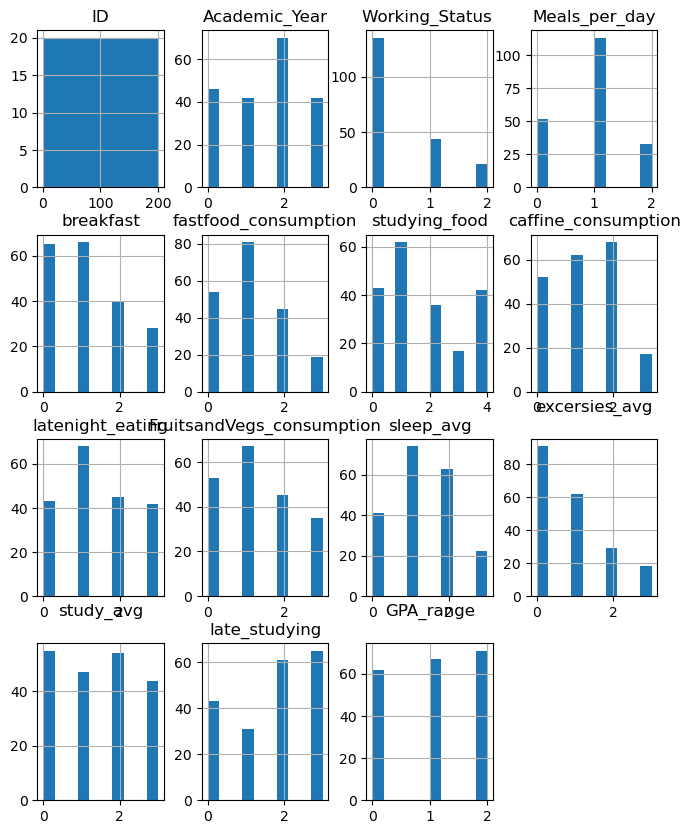

In [6]:
# data distribution for all columns
df.hist(figsize=(8,10));

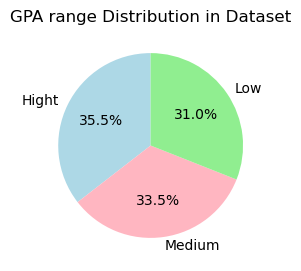

In [7]:
# visualize the distribution of target column(GPA_range)
target_counts = df['GPA_range\n'].value_counts()

labels = ['Hight', 'Medium', 'Low']
colors = ['lightblue', 'lightpink', 'lightgreen']
plt.figure(figsize=(3,3))
plt.pie(target_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors)
plt.title('GPA range Distribution in Dataset')
plt.show()

In [8]:
# dataset information before preprocessing
print("\nDataset Information before preprocessing:")
df.info()


Dataset Information before preprocessing:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         200 non-null    int64  
 1   Academic_Year              200 non-null    int64  
 2   Working_Status             200 non-null    int64  
 3   Meals_per_day              198 non-null    float64
 4   breakfast                  199 non-null    float64
 5   fastfood_consumption       199 non-null    float64
 6   studying_food              200 non-null    int64  
 7   caffine_consumption        199 non-null    float64
 8   latenight_eating           198 non-null    float64
 9   FruitsandVegs_consumption  200 non-null    int64  
 10  sleep_avg                  200 non-null    int64  
 11  excersies_avg
             200 non-null    int64  
 12  study_avg
                 200 non-null    int64  
 13  late_st

In [9]:
# check missing values in each column
print("\nMissing values in each column:")
df.isnull().sum()


Missing values in each column:


ID                           0
Academic_Year                0
Working_Status               0
Meals_per_day                2
breakfast                    1
fastfood_consumption         1
studying_food                0
caffine_consumption          1
latenight_eating             2
FruitsandVegs_consumption    0
sleep_avg                    0
excersies_avg\n              0
study_avg\n                  0
late_studying                0
GPA_range\n                  0
dtype: int64

## Preprocessing

In [11]:
# remove useless columns
df = df.drop("ID",axis=1)

In [12]:
# remove rows with missing values in selected columns
missing_cols = ['Meals_per_day','breakfast','fastfood_consumption','caffine_consumption','latenight_eating']
df.dropna(subset=missing_cols, inplace=True)
df.shape

(195, 14)

In [13]:
df.isnull().sum()

Academic_Year                0
Working_Status               0
Meals_per_day                0
breakfast                    0
fastfood_consumption         0
studying_food                0
caffine_consumption          0
latenight_eating             0
FruitsandVegs_consumption    0
sleep_avg                    0
excersies_avg\n              0
study_avg\n                  0
late_studying                0
GPA_range\n                  0
dtype: int64

In [14]:
df.head()

,Academic_Year,Working_Status,Meals_per_day,breakfast,fastfood_consumption,studying_food,caffine_consumption,latenight_eating,FruitsandVegs_consumption,sleep_avg,excersies_avg\n,study_avg\n,late_studying,GPA_range\n
0,3,1,1.0,1.0,1.0,0,3.0,3.0,3,0,2,1,3,2
1,2,1,0.0,3.0,1.0,4,2.0,3.0,1,1,0,3,3,2
2,2,0,1.0,2.0,1.0,0,2.0,0.0,1,2,2,0,0,1
3,2,0,1.0,1.0,1.0,1,1.0,1.0,2,2,0,2,3,1
4,2,0,0.0,3.0,2.0,4,0.0,1.0,0,2,0,1,1,2


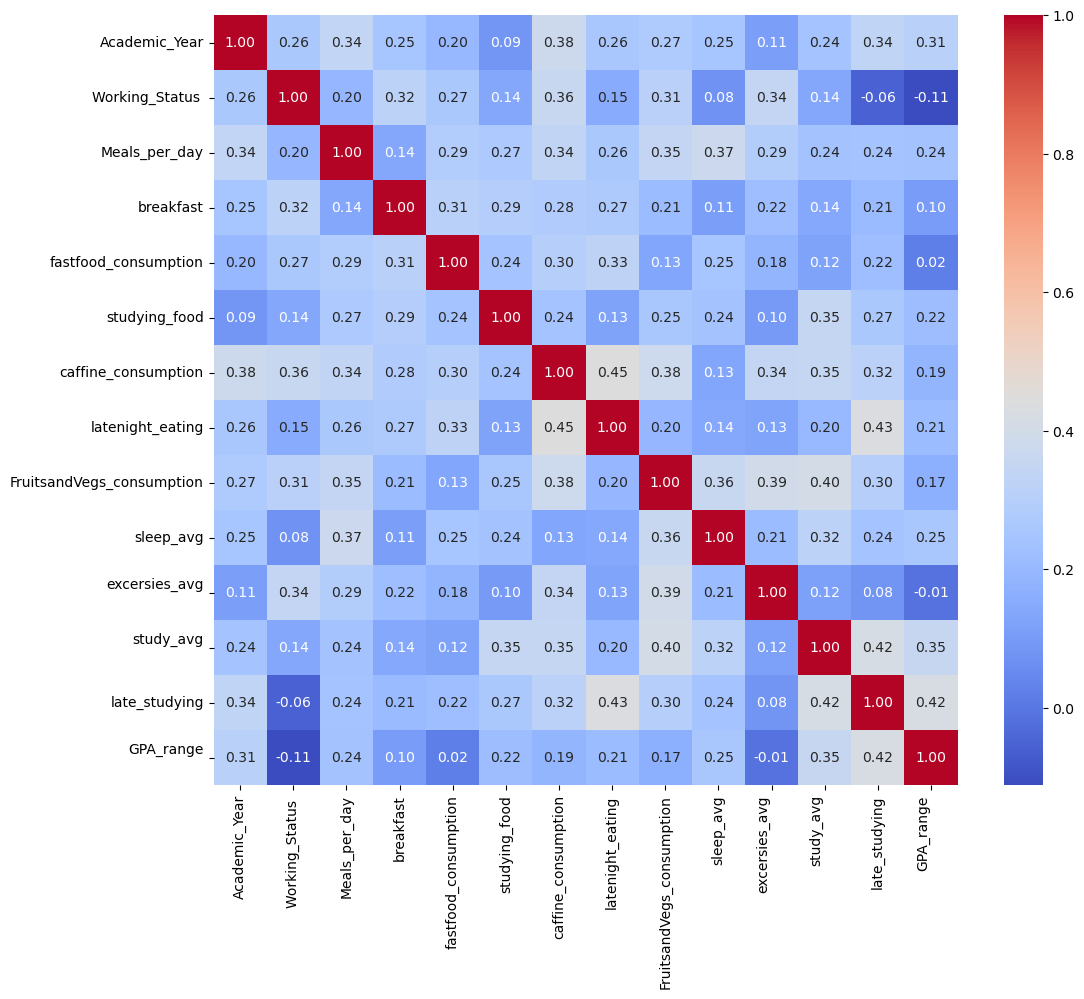

In [15]:
corr_matrix = df.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

# **Build Models**


In [17]:
X = df.iloc[:, :-1].values
y = df.iloc[:, 13].values

In [18]:
#Split Data into Train and Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


#### Logistic Regression

In [20]:
LRclf = LogisticRegression()
#Fitting the model
LRclf.fit(X_train, y_train)

LogisticRegression()

In [21]:
predLR_T = LRclf.predict(X_train)
predLR = LRclf.predict(X_test)

In [22]:
print('Training Accuracy : ', accuracy_score(y_train,predLR_T))
print('Test Accuracy : ', accuracy_score(y_test, predLR))

Training Accuracy :  0.6397058823529411
Test Accuracy :  0.5254237288135594


In [23]:
train_acc = accuracy_score(y_train, LRclf.predict(X_train))
test_acc = accuracy_score(y_test, LRclf.predict(X_test))

print(f"Train Accuracy: {train_acc:.2f}")
print(f"Test Accuracy: {test_acc:.2f}")

if train_acc < 0.7:
    print("model is underfitting")
elif train_acc - test_acc > 0.1:
    print("model is overfitting")
else:
    print("Model is fine")

Train Accuracy: 0.64
Test Accuracy: 0.53
model is underfitting


In [24]:
LR_CR = classification_report(y_test, predLR)
print("Classification Report:",)
print (LR_CR)

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.68      0.65        19
           1       0.40      0.32      0.35        19
           2       0.52      0.57      0.55        21

    accuracy                           0.53        59
   macro avg       0.51      0.52      0.52        59
weighted avg       0.51      0.53      0.52        59



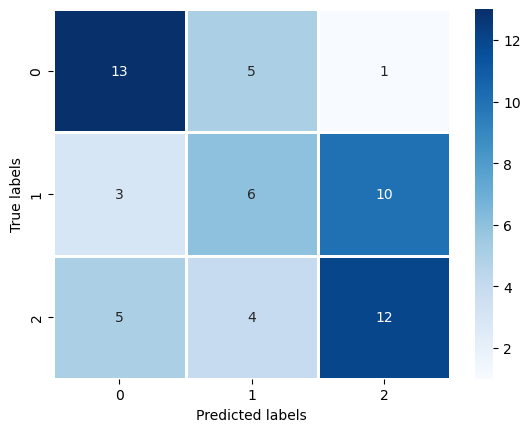

In [25]:
LR_result = confusion_matrix(y_test, predLR)

sns.heatmap(LR_result, annot=True, cmap='Blues', fmt="g", linewidth=2)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.show()

#### Support Vector Machine(SVM)

In [27]:
SVC = svm.SVC()
#Fitting the model
SVC.fit(X_train, y_train)

SVC()

In [28]:
# Make prediction
predSVC_T = SVC.predict(X_train)
predSVC = SVC.predict(X_test)

In [29]:
print('Training Accuracy : ', accuracy_score(y_train,predSVC_T))
print('Test Accuracy : ', accuracy_score(y_test, predSVC))

Training Accuracy :  0.8308823529411765
Test Accuracy :  0.4915254237288136


In [30]:
train_acc = accuracy_score(y_train, SVC.predict(X_train))
test_acc = accuracy_score(y_test, SVC.predict(X_test))

print(f"Train Accuracy: {train_acc:.2f}")
print(f"Test Accuracy: {test_acc:.2f}")

if train_acc < 0.7:
    print("model is underfitting")
elif train_acc - test_acc > 0.1:
    print("model is overfitting")
else:
    print("Model is fine")

Train Accuracy: 0.83
Test Accuracy: 0.49
model is overfitting


In [31]:
svm_CR = classification_report(y_test, predSVC)
print("Classification Report:")
print (svm_CR)

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.53      0.59        19
           1       0.38      0.42      0.40        19
           2       0.48      0.52      0.50        21

    accuracy                           0.49        59
   macro avg       0.51      0.49      0.50        59
weighted avg       0.51      0.49      0.50        59



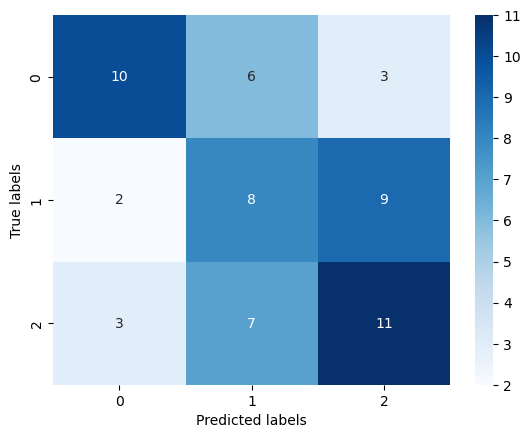

In [32]:
SVM_result = confusion_matrix(y_test, predSVC)
#HeatMap
sns.heatmap(SVM_result, annot=True , cmap='Blues', fmt="g")
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.show()

#### Random Froset

In [34]:
rf = RandomForestClassifier(n_estimators=100,
                            criterion='gini',
                            random_state=42)
#Fitting the model
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [35]:
# Make prediction
predRF_T = rf.predict(X_train)
predRF = rf.predict(X_test)

In [36]:
print("Training Accuracy:", accuracy_score(y_train, predRF_T))
print("Testing Accuracy:", accuracy_score(y_test, predRF))

Training Accuracy: 1.0
Testing Accuracy: 0.4576271186440678


In [37]:
train_acc = accuracy_score(y_train, rf.predict(X_train))
test_acc = accuracy_score(y_test, rf.predict(X_test))

print(f"Train Accuracy: {train_acc:.2f}")
print(f"Test Accuracy: {test_acc:.2f}")

if train_acc < 0.7:
    print("model is underfitting")
elif train_acc - test_acc > 0.1:
    print("model is overfitting")
else:
    print("Model is fine")

Train Accuracy: 1.00
Test Accuracy: 0.46
model is overfitting


In [38]:
rf_CR = classification_report(y_test, predRF)
print("Classification Report:")
print (rf_CR)

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.53      0.62        19
           1       0.28      0.26      0.27        19
           2       0.43      0.57      0.49        21

    accuracy                           0.46        59
   macro avg       0.49      0.45      0.46        59
weighted avg       0.49      0.46      0.46        59



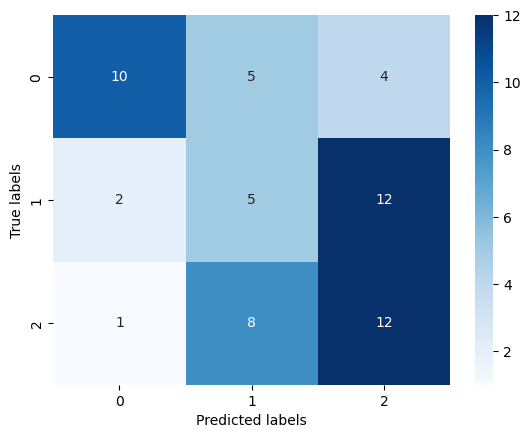

In [39]:
RF_result = confusion_matrix(y_test, predRF)
#HeatMap
sns.heatmap(RF_result, annot=True , cmap='Blues', fmt="g")
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.show()

### Find the worst model

In [42]:
models = {
    'LogisticRegression': LRclf,
    'RandomForest': rf,
    'SVM': SVC}


scores = {}
for name, model in models.items():
    acc = accuracy_score(y_test, model.predict(X_test))
    scores[name] = acc
    print(f"{name} Test Accuracy: {acc}")

worst_model = min(scores, key=scores.get)
print(f"\nWorst model: {worst_model}")

LogisticRegression Test Accuracy: 0.5254237288135594
RandomForest Test Accuracy: 0.4576271186440678
SVM Test Accuracy: 0.4915254237288136

Worst model: RandomForest


# **Scaling Using Standard Scaler**

---



In [47]:
ss_scaler = preprocessing.StandardScaler()
# Rescale the data
X_ss = ss_scaler.fit_transform(X)

In [48]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_ss, y, test_size=0.3, random_state=42, stratify=y)

In [49]:
# Rebuild the Random Forest model using the rescaled data
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train2, y_train2)

RandomForestClassifier(random_state=42)

In [50]:
# Check the performance of the rebuilt model
y_train_pred2 = rf_model.predict(X_train2)
y_pred2 = rf_model.predict(X_test2)

### comparison

In [52]:
# Print accuracy scores
print("Training Accuracy before scaling:", accuracy_score(y_train, predRF_T))
print("Testing Accuracy before scaling :", accuracy_score(y_test, predRF))
print('\nTraining Accuracy after Pre-processing using StandardScaler : ', accuracy_score(y_train2, y_train_pred2))
print('Test Accuracy after Pre-processing using StandardScaler : ', accuracy_score(y_test2, y_pred2))

Training Accuracy before scaling: 1.0
Testing Accuracy before scaling : 0.4576271186440678

Training Accuracy after Pre-processing using StandardScaler :  1.0
Test Accuracy after Pre-processing using StandardScaler :  0.4576271186440678


In [53]:
rf_CR = classification_report(y_test, predRF)
print("Classification Report before scaling:")
print (rf_CR)


CR2 = classification_report(y_test2, y_pred2)
print("\nClassification Report after scaling:")
print(CR2)

Classification Report before scaling:
              precision    recall  f1-score   support

           0       0.77      0.53      0.62        19
           1       0.28      0.26      0.27        19
           2       0.43      0.57      0.49        21

    accuracy                           0.46        59
   macro avg       0.49      0.45      0.46        59
weighted avg       0.49      0.46      0.46        59


Classification Report after scaling:
              precision    recall  f1-score   support

           0       0.71      0.53      0.61        19
           1       0.29      0.26      0.28        19
           2       0.43      0.57      0.49        21

    accuracy                           0.46        59
   macro avg       0.48      0.45      0.46        59
weighted avg       0.48      0.46      0.46        59



# Model Tuning using Grid Search with Cross-Validation


## 1. Logistic Regression

The parameters tuned:
- **C**: controls the regularization strength. A smaller C applies stronger regularization (simpler model), while a larger C allows the model to fit the training data more closely.
- **max_iter**: the maximum number of iterations allowed for the solver to converge.


In [56]:
best_score = 0
for C in [0.01, 0.1, 1, 10, 100]:
    for max_iter in [100, 200, 500]:

        # fit Logistic Regression with current parameters
        model = LogisticRegression(C=C, max_iter=max_iter)
        model.fit(X_train, y_train)
        
        scores = cross_val_score(model, X_train, y_train, cv=5)
        
        score = np.mean(scores)
        
        if score > best_score:
            best_score = score
            best_params = {'C': C, 'max_iter': max_iter}

print(f"Best score: {best_score:.4f}")
print(f"Best parameters: {best_params}")

Best score: 0.5661
Best parameters: {'C': 0.1, 'max_iter': 100}


In [57]:
# Rebuild LR with the best parameters
LR_best = LogisticRegression(C=best_params['C'], max_iter=best_params['max_iter'])
LR_best.fit(X_train, y_train)

# Evaluate tuned model
print('Training Accuracy : ', accuracy_score(y_train, LR_best.predict(X_train)))
print('Test Accuracy : ', accuracy_score(y_test, LR_best.predict(X_test)))

Training Accuracy :  0.6323529411764706
Test Accuracy :  0.4745762711864407


## 2. Support Vector Machine (SVM)

The parameters tuned:
- **gamma**: defines how much influence a single training example has. A larger gamma means closer examples are affected more.
- **C**: trades off misclassification of training examples against simplicity of the decision surface. A low C makes the decision surface smooth, while a high C aims at classifying all training examples correctly.

In [59]:
best_score = 0
for gamma in [0.001, 0.01, 0.1, 1, 10, 100]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:

        model = svm.SVC(gamma=gamma, C=C)
        model.fit(X_train, y_train)
        
        scores = cross_val_score(model, X_train, y_train, cv=5)
        
        score = np.mean(scores)
        
        if score > best_score:
            best_score = score
            best_params = {'C': C, 'gamma': gamma}

print(f"Best score: {best_score:.4f}")
print(f"Best parameters: {best_params}")

Best score: 0.6024
Best parameters: {'C': 100, 'gamma': 0.01}


In [60]:
#SVM with the best parameters
SVM_best = svm.SVC(gamma=best_params['gamma'], C=best_params['C'])
SVM_best.fit(X_train, y_train)

print('Training Accuracy : ', accuracy_score(y_train, SVM_best.predict(X_train)))
print('Test Accuracy : ', accuracy_score(y_test, SVM_best.predict(X_test)))

Training Accuracy :  0.9338235294117647
Test Accuracy :  0.4067796610169492


## 3. Random Forest

Random Forest was identified as the worst-performing model (Test Accuracy: 0.46). Grid Search is applied on the StandardScaler-rescaled data (X_train2, X_test2), consistent with the scaling step already applied to this model.

The parameters tuned:
- **n_estimators**: the number of trees in the forest. More trees generally improve performance but increase computation time.
- **max_depth**: limits how deep each tree can grow. A deeper tree captures more patterns but may overfit on small datasets.

In [62]:
best_score = 0
for n_estimators in [50, 100, 200]:
    for max_depth in [None, 5, 10]:

        model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
        model.fit(X_train2, y_train2)

        scores = cross_val_score(model, X_train2, y_train2, cv=5)

        score = np.mean(scores)

        if score > best_score:
            best_score = score
            best_params = {'n_estimators': n_estimators, 'max_depth': max_depth}

print(f"Best score: {best_score:.4f}")
print(f"Best parameters: {best_params}")

Best score: 0.6468
Best parameters: {'n_estimators': 50, 'max_depth': None}


In [63]:
# Rebuild RF with the best parameters
RF_best = RandomForestClassifier(n_estimators=best_params['n_estimators'], max_depth=best_params['max_depth'], random_state=42)
RF_best.fit(X_train2, y_train2)

# Evaluate the tuned model
print('Training Accuracy : ', accuracy_score(y_train2, RF_best.predict(X_train2)))
print('Test Accuracy : ', accuracy_score(y_test2, RF_best.predict(X_test2)))

Training Accuracy :  1.0
Test Accuracy :  0.4915254237288136


## 4.Comparison: Default vs. Tuned Parameters

The table below compares each model's test accuracy before and after parameter tuning using Grid Search with Cross-Validation.

In [70]:
# Comparison: Default vs Tuned Parameters

print('Logistic Regression - Default Test Accuracy : ', accuracy_score(y_test, LRclf.predict(X_test)))
print('Logistic Regression - Tuned Test Accuracy   : ', accuracy_score(y_test, LR_best.predict(X_test)))

print('SVM - Default Test Accuracy : ', accuracy_score(y_test, SVC.predict(X_test)))
print('SVM - Tuned Test Accuracy   : ', accuracy_score(y_test, SVM_best.predict(X_test)))

print('Random Forest - Default Test Accuracy : ', accuracy_score(y_test2, rf_model.predict(X_test2)))
print('Random Forest - Tuned Test Accuracy   : ', accuracy_score(y_test2, RF_best.predict(X_test2)))

Logistic Regression - Default Test Accuracy :  0.5254237288135594
Logistic Regression - Tuned Test Accuracy   :  0.4745762711864407
SVM - Default Test Accuracy :  0.4915254237288136
SVM - Tuned Test Accuracy   :  0.4067796610169492
Random Forest - Default Test Accuracy :  0.4576271186440678
Random Forest - Tuned Test Accuracy   :  0.4915254237288136
